# 15. Positive Operators, Isometries, QR and Cholesky
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The three possible landscapes of a $2\times2$ energy $x^{\mathsf T}Sx$. Positive definite (left, eigenvalues $3,1$): a bowl, with elliptical level sets. Indefinite (middle, eigenvalues $2,-1$): a saddle, with hyperbolic level sets. Positive semidefinite (right, eigenvalues $2,0$): a trough, flat along the null direction. Below each surface its level curves, with the eigenvectors drawn as principal axes.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


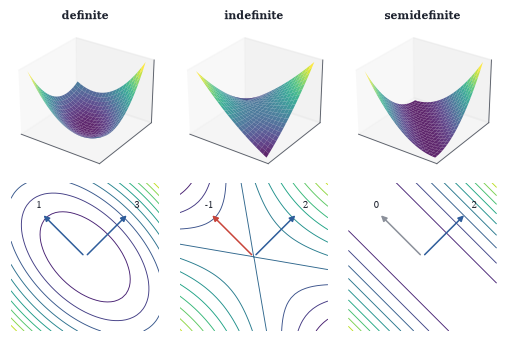

In [2]:
cases = [(np.array([[2.0, 1.0], [1.0, 2.0]]), "definite"), (np.array([[0.5, 1.5], [1.5, 0.5]]), "indefinite"), (np.array([[1.0, 1.0], [1.0, 1.0]]), "semidefinite")]
fig = plt.figure(figsize=(W, 3.0))
g = np.linspace(-1.2, 1.2, 41); X, Y = np.meshgrid(g, g)
for i, (S, name) in enumerate(cases):
    Z = S[0, 0] * X ** 2 + 2 * S[0, 1] * X * Y + S[1, 1] * Y ** 2
    ax = fig.add_subplot(2, 3, i + 1, projection="3d"); ax.plot_surface(X, Y, Z, cmap="viridis", lw=0, alpha=0.85, rstride=2, cstride=2)
    ax.view_init(28, -55); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.set_title(name, fontsize=7)
    ax2 = fig.add_subplot(2, 3, i + 4); ax2.contour(X, Y, Z, levels=10, cmap="viridis", linewidths=0.6)
    lam, Q = np.linalg.eigh(S)
    for k in range(2):
        ax2.annotate("", xy=Q[:, k], xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=RED if lam[k] < 0 else (GRAY if abs(lam[k]) < 1e-9 else BLUE), lw=1))
        ax2.text(*(1.12 * Q[:, k]), f"{int(round(lam[k])) + 0}", fontsize=6)
    ax2.set_aspect("equal"); ax2.axis("off")

Left: the ellipse $5x^2+8xy+5y^2=1$ with its principal axes along the eigenvectors of $S$, of half-lengths $1/\sqrt9$ and $1/\sqrt1$. Right: $1000$ samples of a Gaussian with covariance $\Sigma$ and the ellipses $x^{\mathsf T}\Sigma^{-1}x=c^2$ for $c=1,2$: the data cloud is shaped by the eigenvectors and eigenvalues of its covariance, with standard deviations $\sqrt{\lambda_k}$ along the axes.

(np.float64(-5.0), np.float64(5.0), np.float64(-3.6), np.float64(3.6))

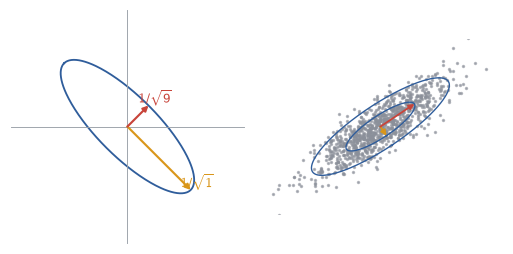

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(W, 2.2))
S = np.array([[5.0, 4.0], [4.0, 5.0]]); lam, Q = np.linalg.eigh(S)
t = np.linspace(0, 2 * np.pi, 300); circ = np.vstack([np.cos(t), np.sin(t)])
E = Q @ np.diag(1 / np.sqrt(lam)) @ circ
ax = axs[0]; plane(ax, 1.3, grid=False); ax.plot(*E, color=BLUE)
for k, col in [(0, GOLD), (1, RED)]:
    arrow(ax, Q[:, k] / np.sqrt(lam[k]) * np.sign(Q[0, k]), color=col, label=f"$1/\\sqrt{{{lam[k]:.0f}}}$")
Sig = np.array([[2.0, 1.2], [1.2, 1.0]]); rng = np.random.default_rng(0)
Lc = np.linalg.cholesky(Sig); pts = Lc @ rng.normal(size=(2, 1000))
ax = axs[1]; ax.scatter(*pts, s=1.5, color=GRAY, alpha=0.6)
lam2, Q2 = np.linalg.eigh(Sig)
for c in (1, 2):
    ax.plot(*(c * Q2 @ np.diag(np.sqrt(lam2)) @ circ), color=BLUE, lw=0.9)
for k, col in [(0, GOLD), (1, RED)]:
    arrow(ax, np.sqrt(lam2[k]) * Q2[:, k] * np.sign(Q2[0, k]), color=col, lw=1.2)
ax.set_aspect("equal"); ax.set_xlim(-5, 5); ax.set_ylim(-3.6, 3.6); ax.axis("off")

The two orthogonal building blocks. Left: a Householder reflection $H=I-2uu^{\mathsf T}$ with $u\propto a-\lVert a\rVert e_1$ reflects $a$ across the mirror line $u^\perp$ (dashed) onto the axis, zeroing its second entry; the shape it carries along (grey to blue) is reflected, reversing orientation. Right: a Givens rotation achieves the same zero by rotating through the angle of $a$, preserving orientation.

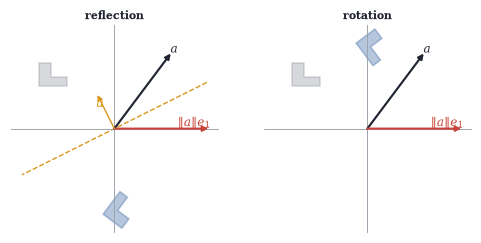

In [4]:
a = np.array([1.2, 1.6]); r = np.array([np.linalg.norm(a), 0]); u = (a - r) / np.linalg.norm(a - r)
H = np.eye(2) - 2 * np.outer(u, u); th = np.arctan2(a[1], a[0]); G = np.array([[np.cos(th), np.sin(th)], [-np.sin(th), np.cos(th)]])
F = np.array([[0, 0.6, 0.6, 0.25, 0.25, 0], [0, 0, 0.2, 0.2, 0.5, 0.5]]) + np.array([[-1.6], [0.9]])
fig, axs = plt.subplots(1, 2, figsize=(W, 2.1))
for ax, M, name in [(axs[0], H, "reflection"), (axs[1], G, "rotation")]:
    plane(ax, 2.2, grid=False); ax.fill(*F, color=GRAY, alpha=0.35); ax.fill(*(M @ F), color=BLUE, alpha=0.35)
    arrow(ax, a, color=INK, label="$a$"); arrow(ax, M @ a, color=RED, label=r"$\|a\|e_1$", offset=(-0.3, 0.12)); ax.set_title(name, fontsize=7)
mirror = np.array([-u[1], u[0]]); axs[0].plot(*np.c_[-2.2 * mirror, 2.2 * mirror], color=GOLD, ls="--", lw=0.9)
arrow(axs[0], 0.8 * u, color=GOLD, lw=0.9, label="$u$", offset=(0.05, -0.2))

In [5]:
A = np.array([[1, 2, 1], [0, 1, -4], [0, 3, 2.]])
Q, R = np.linalg.qr(A); D = np.diag(np.sign(np.diag(R))); Q, R = Q @ D, D @ R      # make diag(R) > 0
print("R =\n", R.round(4), "\nexpected diagonal:", [1, np.sqrt(10), 7 * np.sqrt(10) / 5])
print("A = QR:", np.allclose(Q @ R, A))

R =
 [[1.     2.     1.    ]
 [0.     3.1623 0.6325]
 [0.     0.     4.4272]] 
expected diagonal: [1, np.float64(3.1622776601683795), np.float64(4.427188724235732)]
A = QR: True


Householder QR of a $6\times4$ matrix, step by step. Each panel shows the magnitudes of the entries (darker is larger); one reflection per step zeros the entries below the diagonal in one column, without disturbing the zeros already created. After four reflections the matrix is upper triangular: it is $R$.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


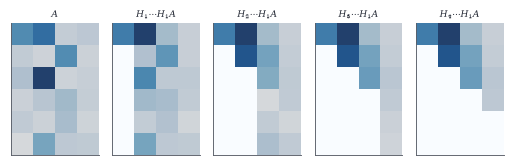

In [6]:
rng = np.random.default_rng(3); M = rng.normal(size=(6, 4)); stages = [M.copy()]
for k in range(4):
    x = M[k:, k]; r = -np.sign(x[0]) * np.linalg.norm(x); v = x.copy(); v[0] -= r; v /= np.linalg.norm(v)
    M[k:, :] -= 2 * np.outer(v, v @ M[k:, :]); stages.append(M.copy())
fig, axs = plt.subplots(1, 5, figsize=(W, 1.4))
for i, (ax, Sg) in enumerate(zip(axs, stages)):
    ax.imshow(np.abs(Sg) > 1e-12, cmap="Greys", vmin=0, vmax=1.6); ax.imshow(np.abs(Sg), cmap="Blues", alpha=0.75)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title("$A$" if i == 0 else f"$H_{i}\\cdots H_1A$", fontsize=6)

In [7]:
def cholesky(S):
    """Plain Cholesky: returns lower triangular L with S = L L^T."""
    n = len(S); L = np.zeros_like(S, dtype=float)
    for j in range(n):
        d = S[j, j] - L[j, :j] @ L[j, :j]
        if d <= 0: raise ValueError(f"not positive definite (pivot {j + 1} = {d:.3g})")
        L[j, j] = np.sqrt(d)
        L[j + 1:, j] = (S[j + 1:, j] - L[j + 1:, :j] @ L[j, :j]) / L[j, j]
    return L
K = 2 * np.eye(4) - np.eye(4, k=1) - np.eye(4, k=-1)
L = cholesky(K); print("L =\n", L.round(4)); print("matches numpy:", np.allclose(L, np.linalg.cholesky(K)))
try: cholesky(np.array([[1, 2], [2, 1.]]))
except ValueError as e: print("indefinite matrix:", e)

L =
 [[ 1.4142  0.      0.      0.    ]
 [-0.7071  1.2247  0.      0.    ]
 [ 0.     -0.8165  1.1547  0.    ]
 [ 0.      0.     -0.866   1.118 ]]
matches numpy: True
indefinite matrix: not positive definite (pivot 2 = -3)


Eigenvalue angles of $2000$ random $20\times20$ unitary matrices. Left: Haar-distributed matrices, produced by QR of complex Gaussian matrices with the diagonal of $R$ made positive; the angles are uniform on the circle. Right: the same QR without the sign correction, whose $Q$ is not uniformly distributed: its eigenvalues avoid the angle $0$.

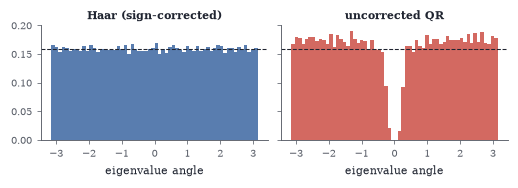

In [8]:
rng = np.random.default_rng(0); n, trials = 20, 2000
ang_good, ang_bad = [], []
for _ in range(trials):
    G = (rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n))) / np.sqrt(2)
    Q, R = np.linalg.qr(G); ang_bad.append(np.angle(np.linalg.eigvals(Q)))
    d = np.diag(R); Q = Q * (d / np.abs(d)); ang_good.append(np.angle(np.linalg.eigvals(Q)))
fig, axs = plt.subplots(1, 2, figsize=(W, 1.6), sharey=True)
bins = np.linspace(-np.pi, np.pi, 61)
axs[0].hist(np.concatenate(ang_good), bins=bins, density=True, color=BLUE, alpha=0.8); axs[0].set_title("Haar (sign-corrected)", fontsize=7)
axs[1].hist(np.concatenate(ang_bad), bins=bins, density=True, color=RED, alpha=0.8); axs[1].set_title("uncorrected QR", fontsize=7)
for ax in axs: ax.axhline(1 / (2 * np.pi), color=INK, ls="--", lw=0.7); ax.set_xlabel("eigenvalue angle")

In [9]:
from scipy.linalg import hilbert
for n in (4, 8, 12):
    print(n, " smallest eigenvalue %.3e" % np.linalg.eigvalsh(hilbert(n)).min(), "  condition number %.2e" % np.linalg.cond(hilbert(n)))

4  smallest eigenvalue 9.670e-05   condition number 1.55e+04
8  smallest eigenvalue 1.112e-10   condition number 1.53e+10
12  smallest eigenvalue 1.089e-16   condition number 1.64e+16


In [10]:
n = 8; F = np.exp(-2j * np.pi * np.outer(np.arange(n), np.arange(n)) / n) / np.sqrt(n)
print("unitary:", np.allclose(F.conj().T @ F, np.eye(n)), "  F^4 = I:", np.allclose(np.linalg.matrix_power(F, 4), np.eye(n)))
print("eigenvalues:", np.round(np.linalg.eigvals(F), 6))

unitary: True   F^4 = I: True
eigenvalues: [-1.-0.j -0.+1.j -1.-0.j  0.-1.j  1.+0.j  1.-0.j  1.+0.j  0.-1.j]


In [11]:
M = np.array([[0, 1, 1, 1], [-1, 0, -1, 1], [-1, 1, 0, -1], [-1, -1, 1, 0]]) / np.sqrt(3)
print("skew:", np.allclose(M.T, -M), " orthogonal:", np.allclose(M.T @ M, np.eye(4)), " eigenvalues:", np.round(np.linalg.eigvals(M), 6))

skew: True  orthogonal: True  eigenvalues: [0.+1.j 0.-1.j 0.+1.j 0.-1.j]
